# Behavioral User Segmentation for a Social App

**Author:** Yelyzaveta Zakharova, Product Analyst
**Data:** fully simulated data of a fictional subscription social discovery app ("Driftly"). No real company data is used.

**Business question.** Product, CRM and marketing all treat users as one average user. Which distinct behavior groups exist,
how much is each worth, and what should each team do differently for them?

**Data.** `users.csv.gz`: 60,000 users active in September 2025, with 30 days of behavior (activity, swiping, matching, messaging, profile)
and outcomes for the **following** 30 days (retention, net revenue). Outcomes are not used for clustering; they validate whether the segments matter.

**Approach.** Behavior features → scaling → k-means with k chosen by fit **and** stability → segment profiles → value check on future outcomes →
simple rules that CRM can implement without the model.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("data/users.csv.gz")
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
user_id,60000.0,530000.50,17320.65,500001.00,515000.75,530000.50,545000.25,560000.00
active_days,60000.0,12.54,6.40,1.00,8.00,12.00,16.00,30.00
swipes,60000.0,1061.54,1354.78,1.00,194.00,475.00,1416.00,16779.00
right_swipe_rate,60000.0,0.36,0.22,0.01,0.18,0.34,0.53,0.97
matches,60000.0,20.82,30.01,0.00,4.00,11.00,26.00,663.00
messages_sent,60000.0,20.32,43.79,0.00,2.00,6.00,18.00,1013.00
reply_rate,57501.0,0.41,0.19,0.01,0.27,0.40,0.54,0.97
photos,60000.0,3.07,2.03,0.00,2.00,3.00,4.00,9.00
bio_filled,60000.0,0.56,0.50,0.00,0.00,1.00,1.00,1.00
premium,60000.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00


## 1. Features
Behavior only. Gender, premium status and future outcomes stay **out** of the clustering and are used to describe and validate segments.
Counts are converted to per-day rates and log-transformed, so a few extreme swipers don't define the clusters.

In [2]:
X = pd.DataFrame({
    "Active days": df.active_days,
    "Sessions per active day": np.log1p(df.sessions / df.active_days),
    "Swipes per active day": np.log1p(df.swipes / df.active_days),
    "Right-swipe rate": df.right_swipe_rate,
    "Match rate": (df.matches / np.maximum(10, df.swipes * df.right_swipe_rate)).clip(upper=(df.matches / np.maximum(10, df.swipes * df.right_swipe_rate)).quantile(.99)),
    "Messages per match": np.log1p(df.messages_sent / np.maximum(1, df.matches)),
    "Reply rate": df.reply_rate.fillna(df.reply_rate.median()),
    "Photos": df.photos, "Bio filled": df.bio_filled, "Push enabled": df.push_enabled,
    "Tenure (log days)": np.log1p(df.tenure_days),
})
Z = StandardScaler().fit_transform(X)
X.corr().round(2)

,Active days,Sessions per active day,Swipes per active day,Right-swipe rate,Match rate,Messages per match,Reply rate,Photos,Bio filled,Push enabled,Tenure (log days)
Active days,1.00,0.40,0.17,-0.06,0.17,0.46,0.26,0.26,0.20,0.18,0.20
Sessions per active day,0.40,1.00,0.49,0.44,-0.24,-0.04,-0.17,0.11,0.08,0.12,0.15
Swipes per active day,0.17,0.49,1.00,0.57,-0.24,0.02,-0.22,0.08,0.06,0.14,-0.09
Right-swipe rate,-0.06,0.44,0.57,1.00,-0.56,-0.37,-0.44,-0.09,-0.07,0.06,-0.11
Match rate,0.17,-0.24,-0.24,-0.56,1.00,0.40,0.33,0.15,0.11,0.03,0.12
Messages per match,0.46,-0.04,0.02,-0.37,0.40,1.00,0.50,0.36,0.27,0.12,0.10
Reply rate,0.26,-0.17,-0.22,-0.44,0.33,0.50,1.00,0.21,0.15,0.04,0.07
Photos,0.26,0.11,0.08,-0.09,0.15,0.36,0.21,1.00,0.20,0.03,0.24
Bio filled,0.20,0.08,0.06,-0.07,0.11,0.27,0.15,0.20,1.00,0.03,0.19
Push enabled,0.18,0.12,0.14,0.06,0.03,0.12,0.04,0.03,0.03,1.00,-0.08


## 2. How many segments?
Two criteria per k: **silhouette** (how separated clusters are) and **stability** (do clusters come back on bootstrap resamples, measured by adjusted Rand index).
A segmentation that changes every time it's re-run is useless for CRM, so stability matters as much as fit.

In [3]:
rng = np.random.default_rng(0)
ks, sil, stab = range(3, 10), [], []
for k in ks:
    km = KMeans(k, n_init=5, random_state=0).fit(Z)
    sil.append(silhouette_score(Z, km.labels_, sample_size=8000, random_state=0))
    aris = []
    for b in range(5):
        idx = rng.choice(len(Z), len(Z), replace=True)
        kb = KMeans(k, n_init=3, random_state=b).fit(Z[idx])
        aris.append(adjusted_rand_score(km.labels_, kb.predict(Z)))
    stab.append(np.mean(aris))
ksel = pd.DataFrame({"silhouette": sil, "stability_ARI": stab}, index=list(ks))
display(ksel.round(3))
K = int(ksel.silhouette.idxmax()); print("Chosen k =", K)

,silhouette,stability_ARI
3,0.201,0.998
4,0.204,0.933
5,0.209,0.977
6,0.212,0.860
7,0.179,0.719
8,0.199,0.715
9,0.186,0.881


Chosen k = 6


Silhouette peaks at k = 6. k = 5 is slightly more stable (0.98 vs 0.86), but merges new users into other groups, and new users need their own onboarding treatment.
So k = 6 is a business choice inside a statistically acceptable range. Absolute silhouette is modest (~0.2), which is normal for behavioral data:
users sit on a continuum, so segment edges are soft. The segments are useful if they differ in value and behavior, which is checked below.

In [4]:
km = KMeans(K, n_init=20, random_state=0).fit(Z)
df["cluster"] = km.labels_
prof = X.assign(cluster=km.labels_).groupby("cluster").median()
# name clusters from their profiles, in order of the most distinctive trait
names, left = {}, set(prof.index)
def pick(col, how, name):
    c = (prof.loc[list(left), col].idxmin() if how == "min" else prof.loc[list(left), col].idxmax())
    names[c] = name; left.discard(c)
pick("Tenure (log days)", "min", "New and unfinished")
pick("Active days", "min", "Fading")
pick("Active days", "max", "Power users")
pick("Right-swipe rate", "max", "Mass swipers")
pick("Messages per match", "max", "Selective talkers")
names[left.pop()] = "Browsers"
df["segment"] = df.cluster.map(names)
ORDER = ["Power users", "Selective talkers", "Mass swipers", "Browsers", "New and unfinished", "Fading"]
prof.index = prof.index.map(names); prof = prof.loc[ORDER]
prof.round(2)

,Active days,Sessions per active day,Swipes per active day,Right-swipe rate,Match rate,Messages per match,Reply rate,Photos,Bio filled,Push enabled,Tenure (log days)
cluster,,,,,,,,,,,
Power users,24.0,1.70,4.63,0.34,0.06,0.96,0.56,5.0,1.0,1.0,5.81
Selective talkers,17.0,1.16,3.46,0.09,0.40,1.06,0.63,4.0,1.0,1.0,5.53
Mass swipers,14.0,1.57,4.98,0.63,0.02,0.29,0.26,3.0,1.0,1.0,5.23
Browsers,10.0,1.22,3.04,0.25,0.10,0.22,0.40,2.0,0.0,1.0,5.49
New and unfinished,8.0,1.16,4.12,0.39,0.05,0.45,0.40,1.0,0.0,1.0,2.77
Fading,6.0,1.20,3.24,0.28,0.09,0.26,0.39,2.0,0.0,0.0,5.52


## 3. Segment profiles (index vs average user)

In [5]:
z = pd.DataFrame(Z, columns=X.columns).assign(segment=df.segment).groupby("segment").mean().loc[ORDER]
z.T.round(2)

segment,Power users,Selective talkers,Mass swipers,Browsers,New and unfinished,Fading
Active days,1.68,0.71,0.22,-0.47,-0.70,-0.73
Sessions per active day,1.40,-0.64,0.94,-0.43,-0.66,-0.53
Swipes per active day,0.71,-0.48,1.04,-0.88,0.18,-0.69
Right-swipe rate,-0.06,-1.15,1.19,-0.47,0.15,-0.34
Match rate,-0.30,1.36,-0.48,-0.05,-0.31,-0.11
Messages per match,1.26,1.55,-0.50,-0.62,-0.12,-0.55
Reply rate,0.77,1.16,-0.72,-0.12,-0.06,-0.17
Photos,0.95,0.71,-0.03,-0.32,-0.71,-0.20
Bio filled,0.70,0.53,-0.03,-0.22,-0.57,-0.15
Push enabled,0.21,0.23,0.22,0.74,0.23,-1.35


## 4. Do segments differ in value? (outcomes in the next 30 days)

In [6]:
val = df.groupby("segment").agg(users=("user_id", "size"), retention_next_30d=("retained_next_30d", "mean"),
                                revenue=("net_revenue_next_30d", "sum"), arpu_next_30d=("net_revenue_next_30d", "mean"),
                                premium_now=("premium", "mean"), push_on=("push_enabled", "mean"), male_share=("gender", lambda g: (g == "male").mean())).loc[ORDER]
val["share_users"] = val.users / val.users.sum(); val["share_revenue"] = val.revenue / val.revenue.sum()
val.round(3)

,users,retention_next_30d,revenue,arpu_next_30d,premium_now,push_on,male_share,share_users,share_revenue
segment,,,,,,,,,
Power users,4950,0.860,65391.19,13.210,0.535,0.743,0.685,0.082,0.505
Selective talkers,9773,0.754,25937.62,2.654,0.104,0.757,0.348,0.163,0.200
Mass swipers,15906,0.522,22818.48,1.435,0.065,0.752,0.878,0.265,0.176
Browsers,9834,0.371,3723.30,0.379,0.028,1.000,0.496,0.164,0.029
New and unfinished,7711,0.384,7232.15,0.938,0.031,0.757,0.597,0.129,0.056
Fading,11826,0.310,4398.82,0.372,0.035,0.000,0.534,0.197,0.034


Segments differ a lot on outcomes they were **not** built on: future retention and revenue. That is the real test of a segmentation.

## 5. Rules CRM can use without the model
A shallow decision tree re-creates the segments from a few raw metrics. If it agrees with k-means most of the time,
CRM and marketing can target segments with simple filters, and the segmentation is explainable.

In [7]:
R = pd.DataFrame({"active_days": df.active_days, "tenure_days": df.tenure_days, "right_swipe_rate": df.right_swipe_rate,
                  "swipes_per_day": df.swipes / df.active_days, "msgs_per_match": df.messages_sent / np.maximum(1, df.matches),
                  "photos": df.photos})
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=300, random_state=0).fit(R, df.segment)
rule_acc = tree.score(R, df.segment)
R["push_enabled"] = df.push_enabled
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=300, random_state=0).fit(R, df.segment)
rule_acc = tree.score(R, df.segment)
print(f"Rules (depth 4, 7 raw metrics) agree with k-means for {rule_acc:.0%} of users")
print(export_text(tree, feature_names=list(R.columns), decimals=2))

Rules (depth 4, 7 raw metrics) agree with k-means for 90% of users
|--- msgs_per_match <= 1.08
|   |--- swipes_per_day <= 71.51
|   |   |--- push_enabled <= 0.50
|   |   |   |--- tenure_days <= 29.50
|   |   |   |   |--- class: New and unfinished
|   |   |   |--- tenure_days >  29.50
|   |   |   |   |--- class: Fading
|   |   |--- push_enabled >  0.50
|   |   |   |--- tenure_days <= 29.50
|   |   |   |   |--- class: New and unfinished
|   |   |   |--- tenure_days >  29.50
|   |   |   |   |--- class: Browsers
|   |--- swipes_per_day >  71.51
|   |   |--- tenure_days <= 29.50
|   |   |   |--- active_days <= 12.50
|   |   |   |   |--- class: New and unfinished
|   |   |   |--- active_days >  12.50
|   |   |   |   |--- class: Mass swipers
|   |   |--- tenure_days >  29.50
|   |   |   |--- active_days <= 5.50
|   |   |   |   |--- class: Fading
|   |   |   |--- active_days >  5.50
|   |   |   |   |--- class: Mass swipers
|--- msgs_per_match >  1.08
|   |--- right_swipe_rate <= 0.22
|   |   |

## 6. Sanity check against the simulation
Because the data is simulated, the true groups are known. This is only possible on synthetic data, but it confirms the method recovers real structure.

In [8]:
lat = pd.read_csv("data/_latent_segment_for_validation_only.csv").segment
ari_true = adjusted_rand_score(lat, df.cluster)
print(f"Adjusted Rand index vs true simulated groups: {ari_true:.2f}")
pd.crosstab(df.segment, lat, normalize="index").loc[ORDER].round(2)

Adjusted Rand index vs true simulated groups: 0.73


segment,fading,lurker,newbie,power,selective,swiper
segment,,,,,,
Power users,0.00,0.00,0.00,0.95,0.04,0.02
Selective talkers,0.00,0.01,0.00,0.00,0.98,0.00
Mass swipers,0.01,0.00,0.00,0.00,0.00,0.99
Browsers,0.31,0.65,0.00,0.00,0.03,0.01
New and unfinished,0.03,0.03,0.92,0.00,0.00,0.02
Fading,0.52,0.45,0.01,0.00,0.02,0.01


## 7. What each team should do

| Segment | Who they are | Action |
|---|---|---|
| Power users | Daily, everything high, most are premium | Protect: early access, loyalty perks; never spam |
| Selective talkers | Swipe little, write a lot, get replies | Best fit for premium upsell built around conversations (read receipts, priority messages) |
| Mass swipers | Mostly men, like almost everyone, rarely write | Swipe-quality nudges, limits with "super like" upsell; lower their exposure weight to protect other users' experience |
| Browsers | Open the app, swipe little, rarely write; push is on | Push-driven activation: "new people near you", profile-completion prompts, guided first like |
| New and unfinished | First month, few photos | Onboarding: photo prompts, first-match push |
| Fading | Active only a few days, and push is **off** for most | Push won't reach them: win-back by e-mail and paid re-engagement, before they churn |

## Charts

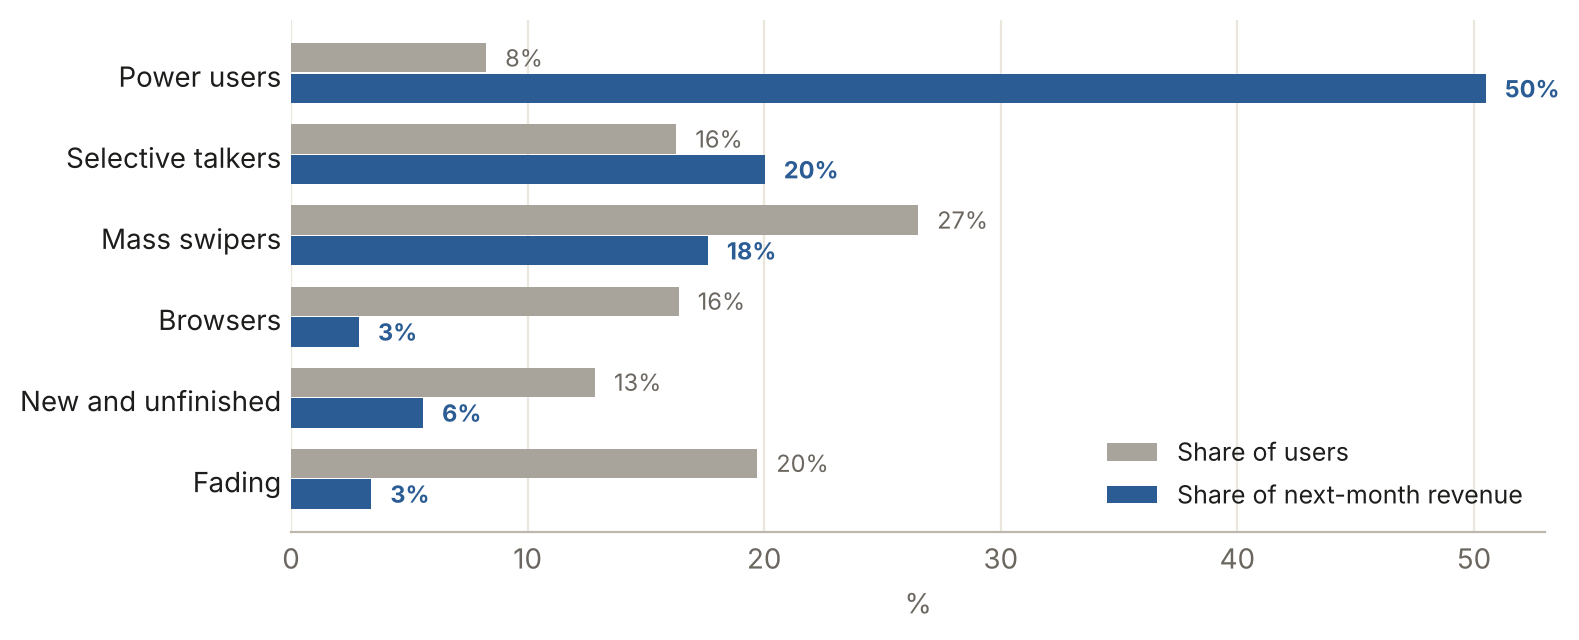

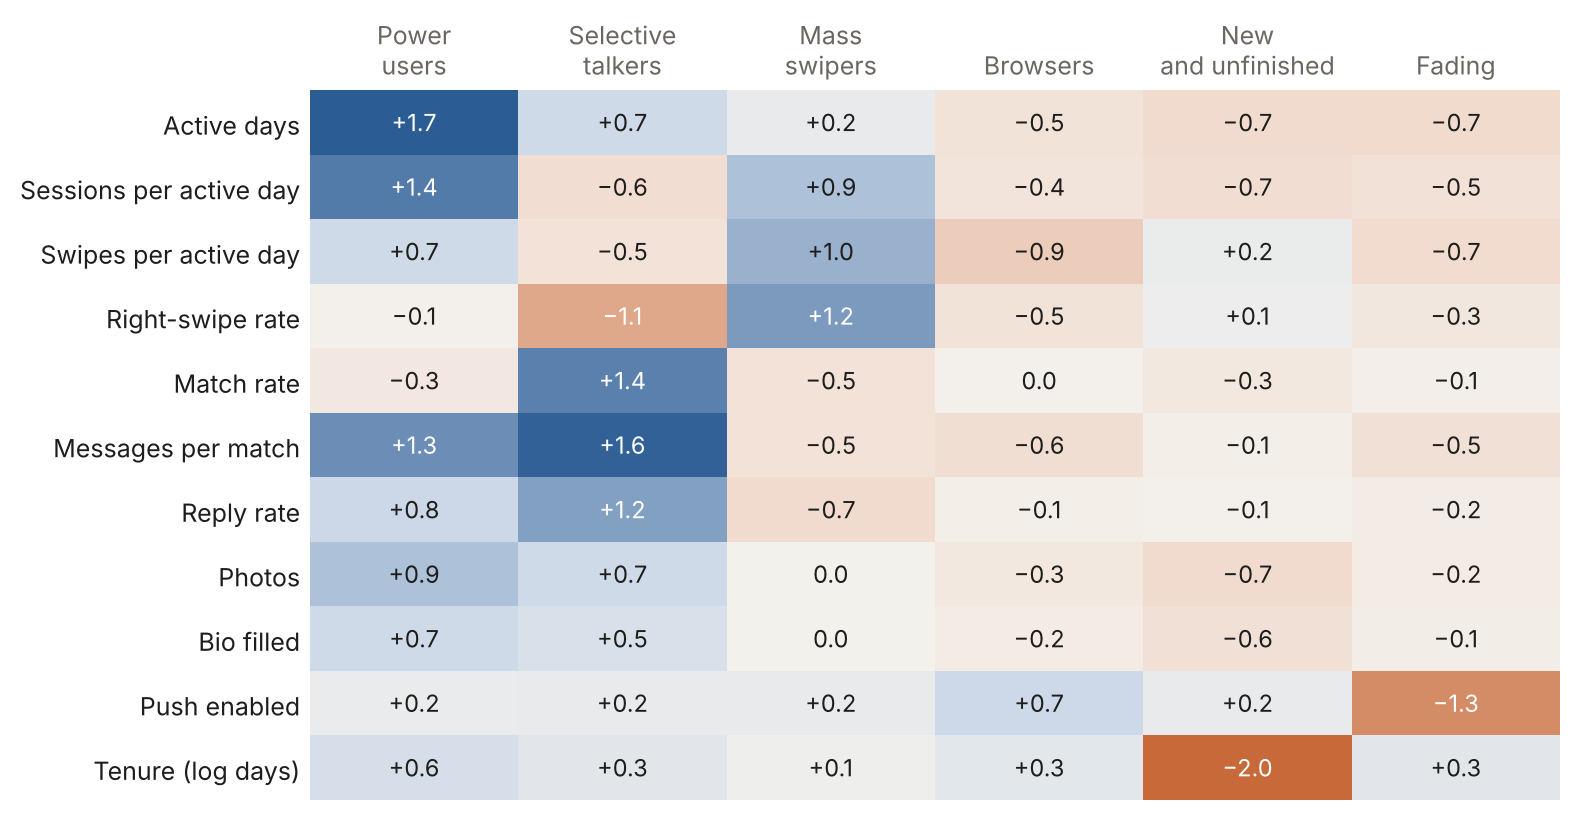

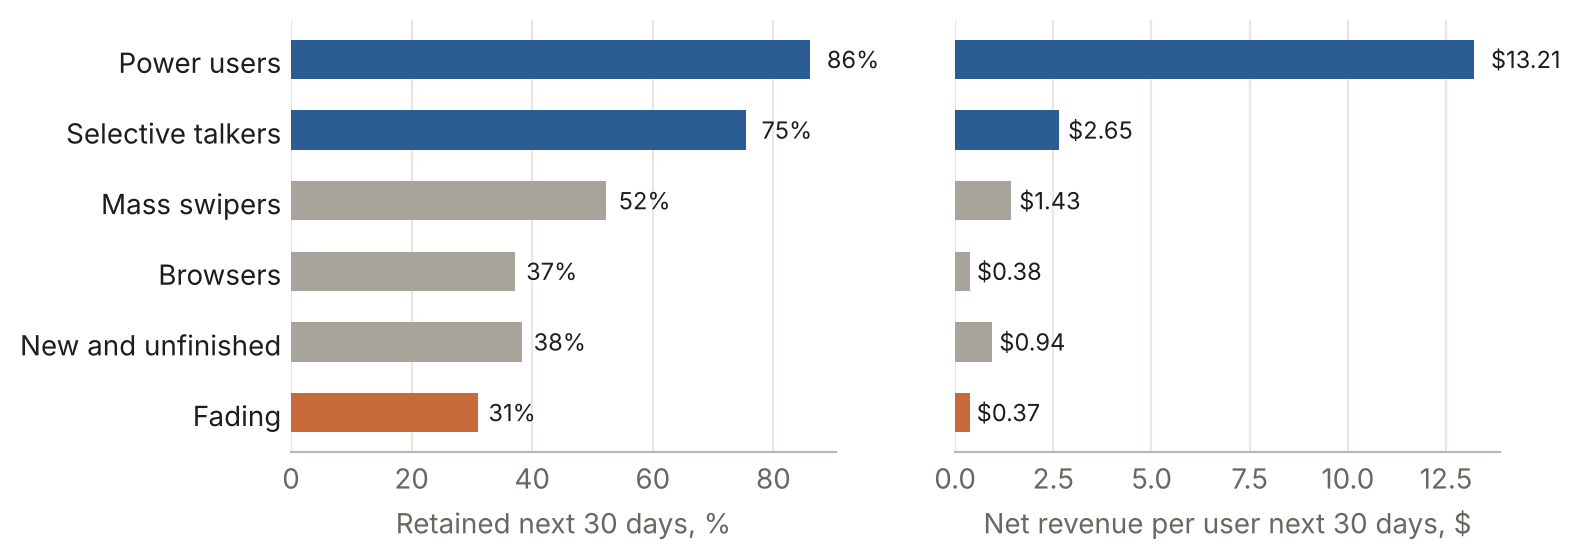

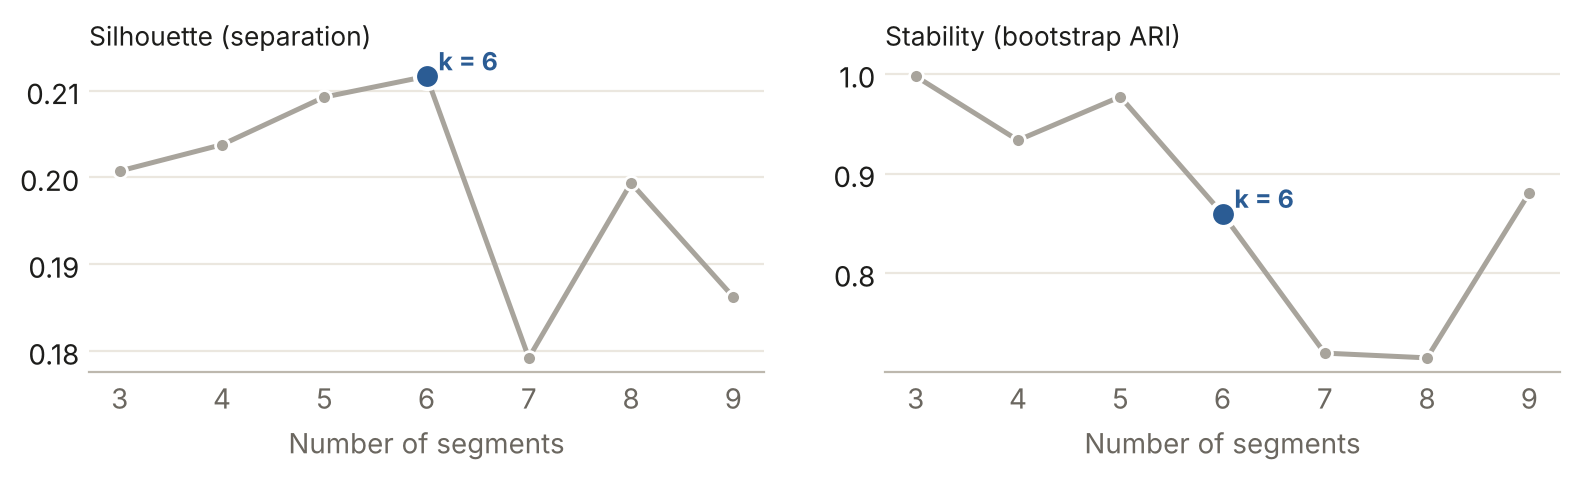

In [9]:
W, M, INK, INK2, RULE, GRID, OTHER = "#2b5c94", "#c8693a", "#1d1d1b", "#6b6760", "#bdb8ae", "#ebe7df", "#a8a49c"
plt.rcParams.update({"font.family": "Inter", "font.size": 10, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": RULE, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0, "savefig.transparent": True})

# E1 users vs revenue share
fig, ax = plt.subplots(figsize=(8, 3.3))
y = np.arange(len(ORDER))[::-1]
ax.barh(y + .19, val.share_users * 100, height=.36, color=OTHER, label="Share of users")
ax.barh(y - .19, val.share_revenue * 100, height=.36, color=W, label="Share of next-month revenue")
for yi, (s, r) in zip(y, val.iterrows()):
    ax.text(r.share_users * 100 + .8, yi + .19, f"{r.share_users*100:.0f}%", va="center", fontsize=8.5, color=INK2)
    ax.text(r.share_revenue * 100 + .8, yi - .19, f"{r.share_revenue*100:.0f}%", va="center", fontsize=8.5, color=W, fontweight="bold")
ax.set_yticks(y, ORDER); ax.set_xlabel("%"); ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e1_value.png", dpi=240)

# E2 profile heatmap (diverging, z-score vs average)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", ["#c8693a", "#f1d9cb", "#f4f2ee", "#cbd8e8", "#2b5c94"])
zz = z.T.clip(-1.6, 1.6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.imshow(zz.values, cmap=cmap, vmin=-1.6, vmax=1.6, aspect="auto")
for i in range(zz.shape[0]):
    for j in range(zz.shape[1]):
        v = z.T.values[i, j]
        ax.text(j, i, "0.0" if abs(v) < 0.05 else f"{v:+.1f}".replace("-", "−"), ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 1.1 else INK)
ax.set_xticks(range(len(ORDER)), [o.replace(" ", "\n", 1) for o in ORDER], fontsize=9)
ax.set_yticks(range(len(zz.index)), zz.index, fontsize=9)
ax.tick_params(axis="x", top=True, bottom=False, labeltop=True, labelbottom=False)
for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); fig.savefig("charts/e2_profiles.png", dpi=240)

# E3 retention + ARPU
fig, axes = plt.subplots(1, 2, figsize=(8, 2.9), sharey=True)
y = np.arange(len(ORDER))[::-1]
for ax, col, lab, fmt in [(axes[0], "retention_next_30d", "Retained next 30 days, %", lambda v: f"{v*100:.0f}%"),
                          (axes[1], "arpu_next_30d", "Net revenue per user next 30 days, $", lambda v: f"${v:.2f}")]:
    vals = val[col] * (100 if "retention" in col else 1)
    ax.barh(y, vals, color=[W if s in ("Power users", "Selective talkers") else (M if s == "Fading" else OTHER) for s in ORDER], height=.56)
    for yi, v in zip(y, val[col]):
        ax.text((v * (100 if "retention" in col else 1)) * 1.02, yi, " " + fmt(v), va="center", fontsize=8.5)
    ax.set_xlabel(lab); ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
axes[0].set_yticks(y, ORDER)
fig.tight_layout(w_pad=2); fig.savefig("charts/e3_outcomes.png", dpi=240)

# E4 k selection
fig, axes = plt.subplots(1, 2, figsize=(8, 2.5))
for ax, col, lab in [(axes[0], "silhouette", "Silhouette (separation)"), (axes[1], "stability_ARI", "Stability (bootstrap ARI)")]:
    ax.plot(ksel.index, ksel[col], color=OTHER, lw=1.8, marker="o", ms=5, mec="white")
    ax.plot(K, ksel.loc[K, col], "o", color=W, ms=9, mec="white", mew=1.5, zorder=3)
    ax.text(K, ksel.loc[K, col], f"  k = {K}", color=W, fontweight="bold", fontsize=9, va="bottom")
    ax.set_title(lab, loc="left", fontsize=9.5); ax.set_xticks(list(ks)); ax.set_xlabel("Number of segments")
    ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(w_pad=2.5); fig.savefig("charts/e4_k.png", dpi=240)
plt.show()

In [10]:
out = dict(K=K, ksel=ksel.to_dict(), val=val.reset_index().to_dict("records"), z=z.to_dict("index"),
           prof=prof.to_dict("index"), rule_acc=rule_acc, ari_true=ari_true, n=len(df),
           rules=export_text(tree, feature_names=list(R.columns), decimals=2))
json.dump(out, open("results.json", "w"), default=float, indent=1)